# Diabetes Prediction System
## An End-to-End Machine Learning Classification Project
**Name:** Mahin Hasnat

**Project Type:** Individual Project

**Dataset:** CDC Diabetes Health Indicators (BRFSS 2015)

**Dataset Size:** 253,680 Survey Records

**Input Features:** 21

**Task:** Binary Classification

**Course:** Shohojcoding MLB Batch-2

**Instructor:** Md. Mahabub Hasan Mamun

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [66]:
import pandas as pd

df = pd.read_csv("/content/diabetes_binary_health_indicators_BRFSS2015 - diabetes_binary_health_indicators_BRFSS2015.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [67]:
print("Dataset Shape:", df.shape)

Dataset Shape: (253680, 22)


In [68]:
df.head()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,1,1,1,40,1,0,0,0,0,...,1,0,5,18,15,1,0,9,4,3
1,0,0,0,0,25,1,0,0,1,0,...,0,1,3,0,0,0,0,7,6,1
2,0,1,1,1,28,0,0,0,0,1,...,1,1,5,30,30,1,0,9,4,8
3,0,1,0,1,27,0,0,0,1,1,...,1,0,2,0,0,0,0,11,3,6
4,0,1,1,1,24,0,0,0,1,1,...,1,0,2,3,0,0,0,11,5,4


In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   Diabetes_binary       253680 non-null  int64
 1   HighBP                253680 non-null  int64
 2   HighChol              253680 non-null  int64
 3   CholCheck             253680 non-null  int64
 4   BMI                   253680 non-null  int64
 5   Smoker                253680 non-null  int64
 6   Stroke                253680 non-null  int64
 7   HeartDiseaseorAttack  253680 non-null  int64
 8   PhysActivity          253680 non-null  int64
 9   Fruits                253680 non-null  int64
 10  Veggies               253680 non-null  int64
 11  HvyAlcoholConsump     253680 non-null  int64
 12  AnyHealthcare         253680 non-null  int64
 13  NoDocbcCost           253680 non-null  int64
 14  GenHlth               253680 non-null  int64
 15  MentHlth              253680 non-n

In [70]:
df.describe()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
count,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,...,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000
mean,0.139333,0.429001,0.424121,0.962670,28.382364,0.443169,0.040571,0.094186,0.756544,0.634256,...,0.951053,0.084177,2.511392,3.184772,4.242081,0.168224,0.440342,8.032119,5.050434,6.053875
std,0.346294,0.494934,0.494210,0.189571,6.608694,0.496761,0.197294,0.292087,0.429169,0.481639,...,0.215759,0.277654,1.068477,7.412847,8.717951,0.374066,0.496429,3.054220,0.985774,2.071148
min,0.000000,0.000000,0.000000,0.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,1.000000,24.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,6.000000,4.000000,5.000000
50%,0.000000,0.000000,0.000000,1.000000,27.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,8.000000,5.000000,7.000000
75%,0.000000,1.000000,1.000000,1.000000,31.000000,1.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,1.000000,10.000000,6.000000,8.000000
max,1.000000,1.000000,1.000000,1.000000,98.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,5.000000,30.000000,30.000000,1.000000,1.000000,13.000000,6.000000,8.000000


In [71]:
df.isnull().sum()

,0
Diabetes_binary,0
HighBP,0
HighChol,0
CholCheck,0
BMI,0
Smoker,0
Stroke,0
HeartDiseaseorAttack,0
PhysActivity,0
Fruits,0


In [72]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 24206


In [73]:
target = "Diabetes_binary"

print("Target Column:", target)
print("Target Values:")
print(df[target].unique())

Target Column: Diabetes_binary
Target Values:
[0 1]


In [74]:
binary_features = [
    "HighBP",
    "HighChol",
    "CholCheck",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "DiffWalk",
    "Sex"
]

print("Binary Features:", len(binary_features))

Binary Features: 14


In [75]:
ordinal_features = [
    "GenHlth",
    "Age",
    "Education",
    "Income"
]

print("Ordinal Features:", len(ordinal_features))

Ordinal Features: 4


In [76]:
numeric_features = [
    "BMI",
    "MentHlth",
    "PhysHlth"
]

print("Numeric Features:", len(numeric_features))

Numeric Features: 3


In [77]:
df[target].value_counts()

,count
Diabetes_binary,
0,218334
1,35346


In [78]:
df[target].value_counts(normalize=True) * 100

,proportion
Diabetes_binary,
0,86.066698
1,13.933302


### Initial Dataset Observations

1. The dataset contains 253,680 survey records and 22 columns.

2. There are 21 predictor features and one target variable.

3. The target variable represents two classes: 0 and 1.

4. The dataset contains binary, ordinal and numeric features.

5. The class distribution will help us understand the imbalance between the two target classes.

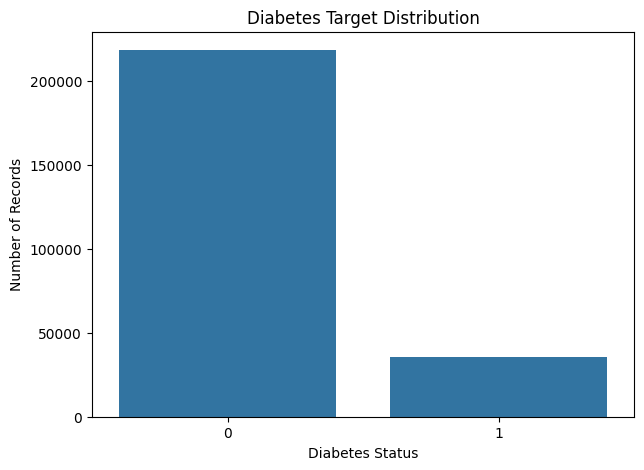

In [79]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Diabetes_binary"
)

plt.title("Diabetes Target Distribution")
plt.xlabel("Diabetes Status")
plt.ylabel("Number of Records")

plt.show()

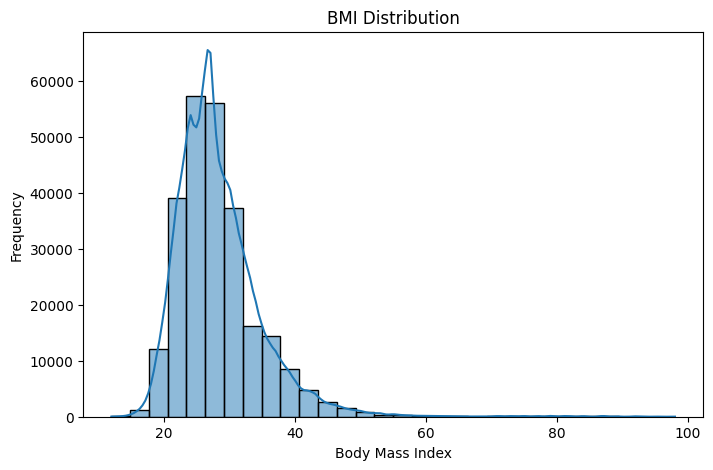

In [80]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="BMI",
    bins=30,
    kde=True
)

plt.title("BMI Distribution")
plt.xlabel("Body Mass Index")
plt.ylabel("Frequency")

plt.show()

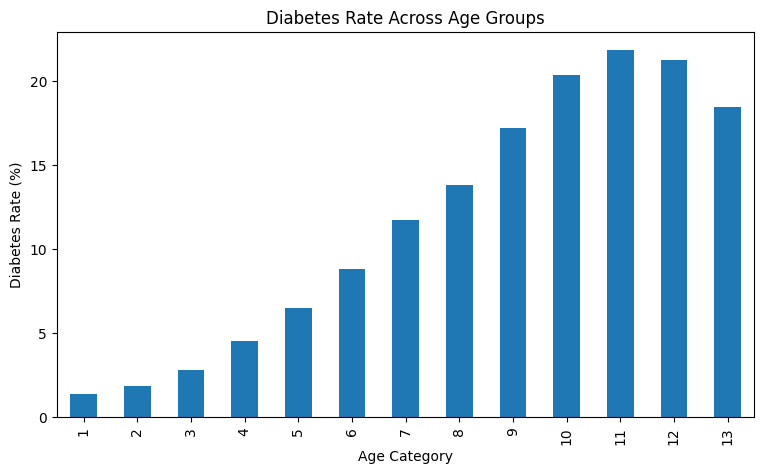

In [81]:
age_rate = df.groupby("Age")["Diabetes_binary"].mean() * 100

plt.figure(figsize=(9, 5))

age_rate.plot(kind="bar")

plt.title("Diabetes Rate Across Age Groups")
plt.xlabel("Age Category")
plt.ylabel("Diabetes Rate (%)")

plt.show()

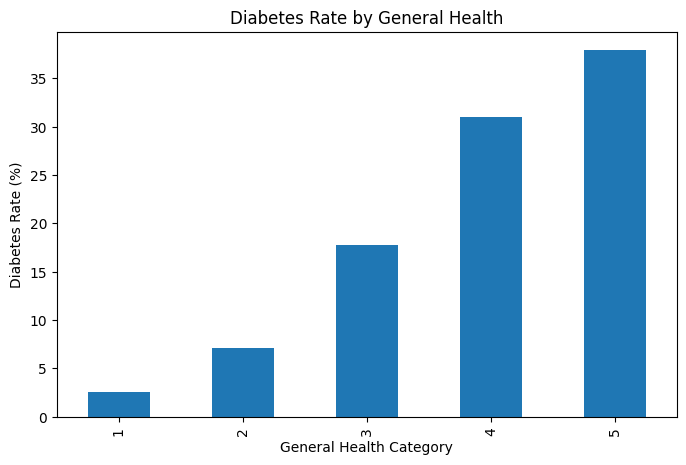

In [82]:
health_rate = df.groupby("GenHlth")["Diabetes_binary"].mean() * 100

plt.figure(figsize=(8, 5))
health_rate.plot(kind="bar")
plt.title("Diabetes Rate by General Health")
plt.xlabel("General Health Category")
plt.ylabel("Diabetes Rate (%)")

plt.show()

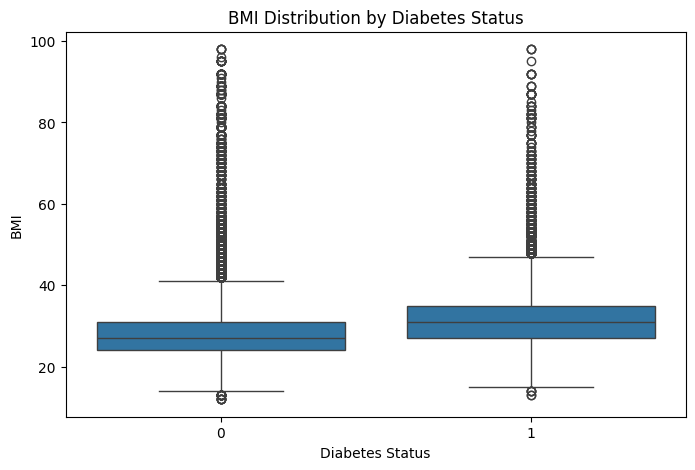

In [83]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Diabetes_binary",
    y="BMI"
)

plt.title("BMI Distribution by Diabetes Status")
plt.xlabel("Diabetes Status")
plt.ylabel("BMI")

plt.show()

## Exploratory Data Analysis Findings

1. The target distribution shows the proportion of positive and negative diabetes indicators.

2. The BMI histogram illustrates the distribution of BMI values.

3. The age-group analysis shows differences in diabetes-indicator rates across age categories.

4. The general-health analysis shows variations in diabetes-indicator rates across health categories.

5. The BMI boxplot compares BMI distributions between the two target classes.

6. These findings describe associations in survey data and do not establish causation.

In [84]:
X = df.drop("Diabetes_binary", axis=1)
y = df["Diabetes_binary"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (253680, 21)
Target Shape: (253680,)


In [85]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (202944, 21)
Testing Data: (50736, 21)


In [86]:
print("Training Missing Values:")
print(X_train.isnull().sum().sum())
print("Testing Missing Values:")
print(X_test.isnull().sum().sum())

Training Missing Values:
0
Testing Missing Values:
0


In [87]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [88]:
numeric_ordinal_features = numeric_features + ordinal_features

In [89]:
numeric_ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [90]:
binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

In [91]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric_ordinal", numeric_ordinal_pipeline, numeric_ordinal_features),
        ("binary", binary_pipeline, binary_features)
    ]
)

In [92]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [93]:
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric_ordinal',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['BMI', 'MentHlth',
                                                   'PhysHlth', 'GenHlth', 'Age',
                                                   'Education', 'Income']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['HighBP', 'HighChol',
                                                   'CholCheck', 'Smoker',
                                                   'Stroke',
                                                   'HeartDiseaseorAttack',
                                                   'PhysActivity', 'Fruits',
                                                   'Veggies',
                                                   'HvyAlcoholConsump',
                                                   'AnyHealthcare',
                                                   'NoDocbcCost', 'DiffWalk',
                                                   'Sex'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [94]:
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

In [95]:
random_forest_model.fit(X_train, y_train)

print("Random Forest Training Completed!")

Random Forest Training Completed!


In [96]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

In [97]:
logistic_predictions = logistic_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

In [98]:
rf_predictions = random_forest_model.predict(X_test)
rf_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

In [99]:
def evaluate_model(y_true, predictions, probabilities):

    print("Accuracy:", accuracy_score(y_true, predictions))
    print("Precision:", precision_score(y_true, predictions, zero_division=0))
    print("Recall:", recall_score(y_true, predictions, zero_division=0))
    print("F1 Score:", f1_score(y_true, predictions, zero_division=0))
    print("ROC-AUC:", roc_auc_score(y_true, probabilities))
    print("PR-AUC:", average_precision_score(y_true, probabilities))

In [100]:
evaluate_model(
    y_test,
    logistic_predictions,
    logistic_probabilities
)

Accuracy: 0.8620703248186692
Precision: 0.5164275798241554
Recall: 0.157872400622436
F1 Score: 0.24182015167930662
ROC-AUC: 0.8192299426520216
PR-AUC: 0.3942441070073419


In [101]:
evaluate_model(
    y_test,
    rf_predictions,
    rf_probabilities
)

Accuracy: 0.8596657205928729
Precision: 0.49000392003136023
Recall: 0.17682840571509406
F1 Score: 0.2598752598752599
ROC-AUC: 0.7948658869583732
PR-AUC: 0.36795063020696894


In [102]:
results = pd.DataFrame({

    "Model": ["Logistic Regression", "Random Forest"],

    "Accuracy": [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, rf_predictions)
    ],

    "Precision": [
        precision_score(y_test, logistic_predictions),
        precision_score(y_test, rf_predictions)
    ],

    "Recall": [
        recall_score(y_test, logistic_predictions),
        recall_score(y_test, rf_predictions)
    ],

    "F1 Score": [
        f1_score(y_test, logistic_predictions),
        f1_score(y_test, rf_predictions)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, logistic_probabilities),
        roc_auc_score(y_test, rf_probabilities)
    ],

    "PR-AUC": [
        average_precision_score(y_test, logistic_probabilities),
        average_precision_score(y_test, rf_probabilities)
    ]

})

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.862070,0.516428,0.157872,0.241820,0.819230,0.394244
1,Random Forest,0.859666,0.490004,0.176828,0.259875,0.794866,0.367951


In [103]:
majority_class_accuracy = y_test.value_counts(normalize=True).max()
positive_prevalence = y_test.mean()

print("Majority Class Baseline:", majority_class_accuracy)
print("Positive Class Prevalence:", positive_prevalence)

Majority Class Baseline: 0.8606709239987386
Positive Class Prevalence: 0.13932907600126143


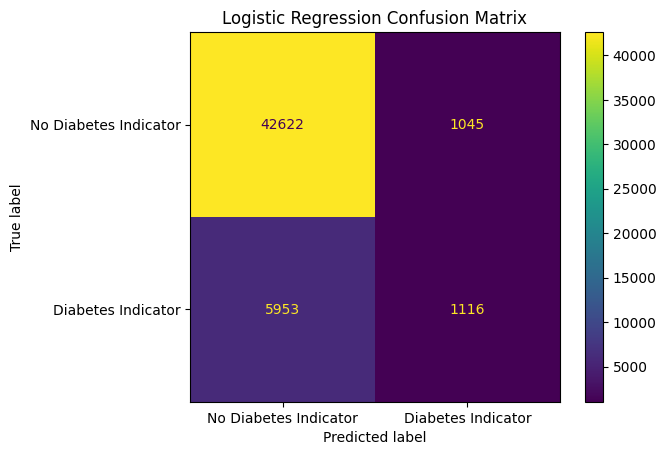

In [104]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    display_labels=["No Diabetes Indicator", "Diabetes Indicator"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

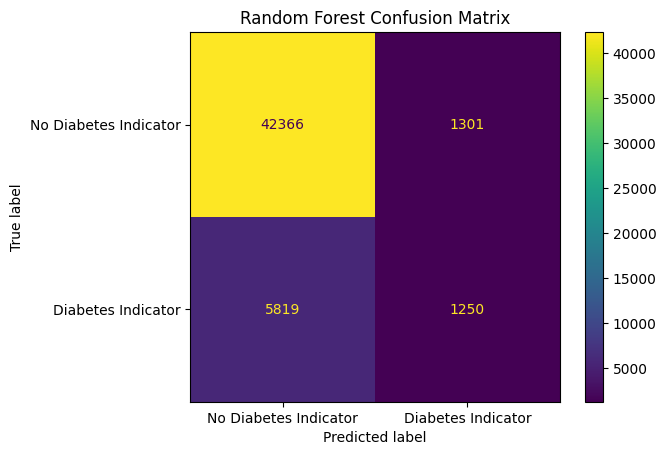

In [105]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=["No Diabetes Indicator", "Diabetes Indicator"]
)

plt.title("Random Forest Confusion Matrix")

plt.show()

In [106]:
print("Logistic Regression Report")
print(classification_report(y_test, logistic_predictions))

Logistic Regression Report
              precision    recall  f1-score   support

           0       0.88      0.98      0.92     43667
           1       0.52      0.16      0.24      7069

    accuracy                           0.86     50736
   macro avg       0.70      0.57      0.58     50736
weighted avg       0.83      0.86      0.83     50736



<Figure size 800x600 with 0 Axes>

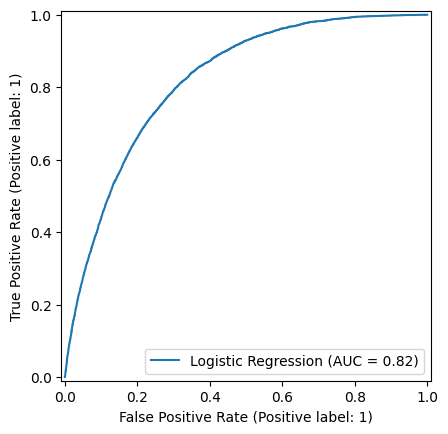

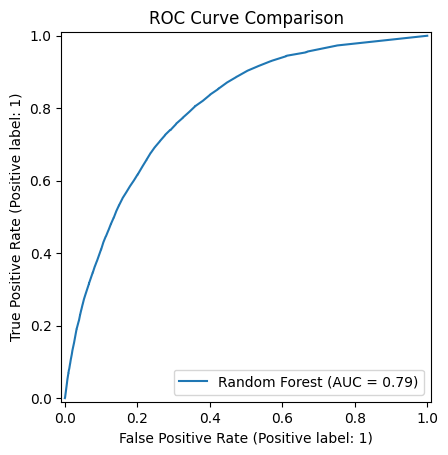

In [107]:
plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    logistic_probabilities,
    name="Logistic Regression"
)

RocCurveDisplay.from_predictions(
    y_test,
    rf_probabilities,
    name="Random Forest"
)

plt.title("ROC Curve Comparison")

plt.show()

<Figure size 800x600 with 0 Axes>

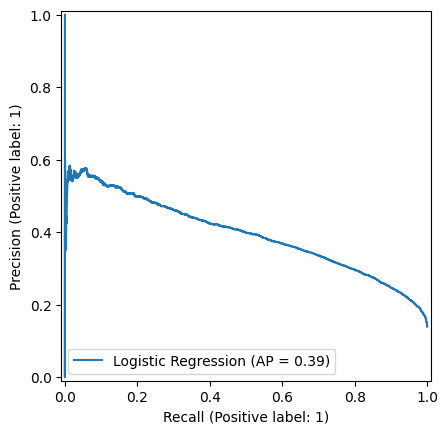

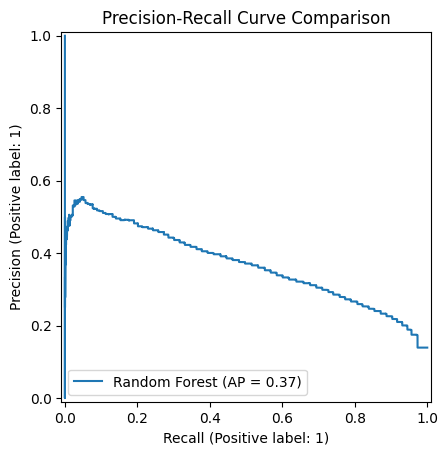

In [108]:
plt.figure(figsize=(8, 6))

PrecisionRecallDisplay.from_predictions(
    y_test,
    logistic_probabilities,
    name="Logistic Regression"
)

PrecisionRecallDisplay.from_predictions(
    y_test,
    rf_probabilities,
    name="Random Forest"
)

plt.title("Precision-Recall Curve Comparison")

plt.show()

## Understanding Classification Errors

- True Positive (TP): Correctly predicted positive cases.
- True Negative (TN): Correctly predicted negative cases.
- False Positive (FP): Negative cases incorrectly predicted as positive.
- False Negative (FN): Positive cases incorrectly predicted as negative.

A higher recall can help identify more positive cases, but it may also increase false positives.

Model performance must be evaluated using multiple metrics rather than accuracy alone.

In [109]:
best_model = logistic_model
print("Selected Model:", best_model)

Selected Model: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric_ordinal',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['BMI', 'MentHlth',
                                                   'PhysHlth', 'GenHlth', 'Age',
                                                   'Education', 'Income']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['HighBP', 

In [110]:
example_1 = {
    "HighBP": 1,
    "HighChol": 1,
    "CholCheck": 1,
    "BMI": 28,
    "Smoker": 0,
    "Stroke": 0,
    "HeartDiseaseorAttack": 0,
    "PhysActivity": 1,
    "Fruits": 1,
    "Veggies": 1,
    "HvyAlcoholConsump": 0,
    "AnyHealthcare": 1,
    "NoDocbcCost": 0,
    "GenHlth": 3,
    "MentHlth": 5,
    "PhysHlth": 5,
    "DiffWalk": 0,
    "Sex": 1,
    "Age": 8,
    "Education": 5,
    "Income": 6
}

In [111]:
example_2 = {
    "HighBP": 0,
    "HighChol": 0,
    "CholCheck": 1,
    "BMI": 23,
    "Smoker": 0,
    "Stroke": 0,
    "HeartDiseaseorAttack": 0,
    "PhysActivity": 1,
    "Fruits": 1,
    "Veggies": 1,
    "HvyAlcoholConsump": 0,
    "AnyHealthcare": 1,
    "NoDocbcCost": 0,
    "GenHlth": 2,
    "MentHlth": 0,
    "PhysHlth": 0,
    "DiffWalk": 0,
    "Sex": 0,
    "Age": 4,
    "Education": 6,
    "Income": 8
}

In [112]:
demo_data = pd.DataFrame([
    example_1,
    example_2
])

demo_data = demo_data[X.columns]
demo_data

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,1,1,1,28,0,0,0,1,1,1,...,1,0,3,5,5,0,1,8,5,6
1,0,0,1,23,0,0,0,1,1,1,...,1,0,2,0,0,0,0,4,6,8


In [113]:
valid_ranges = {
    "BMI": (12, 98),
    "MentHlth": (0, 30),
    "PhysHlth": (0, 30),
    "GenHlth": (1, 5),
    "Age": (1, 13),
    "Education": (1, 6),
    "Income": (1, 8)
}

for column, (minimum, maximum) in valid_ranges.items():

    if not demo_data[column].between(minimum, maximum).all():
        raise ValueError(f"Invalid value in {column}")

for column in binary_features:

    if not demo_data[column].isin([0, 1]).all():
        raise ValueError(f"Invalid binary value in {column}")

print("All input values are valid!")

All input values are valid!


In [114]:
predictions = best_model.predict(demo_data)
probabilities = best_model.predict_proba(demo_data)[:, 1]

for i in range(len(predictions)):

    print(f"Example {i+1}")
    print("Predicted Class:", predictions[i])
    print("Estimated Class Probability:", probabilities[i])
    print("---------------------------")

Example 1
Predicted Class: 0
Estimated Class Probability: 0.2173580083975795
---------------------------
Example 2
Predicted Class: 0
Estimated Class Probability: 0.013441448224476845
---------------------------


# Conclusion and Reflection

## Best Model

*   List item
*   List item



The best-performing model was selected based on multiple classification metrics, including precision, recall, F1-score, ROC-AUC and PR-AUC.

## Key Findings

The exploratory data analysis revealed differences in diabetes-indicator rates across age groups and general health categories.

## Limitations

1. The dataset is based on self-reported survey responses.
2. The survey data comes from 2015 and may not represent current populations.
3. Demographic differences may introduce bias.
4. Changes in diabetes prevalence may affect model performance.
5. The model has not undergone external clinical validation.

## Responsible Use

This project is developed for educational purposes only.

It is not a medical diagnosis system and must not be used to make medical decisions or recommend treatments.